# Ngwerere: de video a caudal con pyorc

Notebook autocontenido que resume los ejemplos `01` a `04` de `pyorc_repo/examples` en un
solo flujo de trabajo, con comentarios linea por linea.

Pasos:

1. Abrir el video y extraer un fotograma
2. Definir los puntos de control (GCPs) que ligan pixeles con coordenadas reales
3. Construir la configuracion de camara y reproyectar (ortorectificar)
4. Calcular velocidades superficiales con LSPIV y filtrar las espurias
5. Muestrear un transecto batimetrico e integrar el caudal

Resultado esperado, igual que el ejemplo original (seccion transversal #1):
mediana de 0.164 m3/s, con P5 de 0.076 y P95 de 0.222 m3/s.

**Los datos de entrada se leen en modo solo lectura de la carpeta `ngwerere/` del
repositorio. Todo lo que este notebook genera (JSON de camara, NetCDF de velocimetria,
CSV de resultados y figuras PNG) se escribe en la subcarpeta `salidas/` de esta misma
carpeta, con nombres propios, para no sobrescribir nada del ejemplo original.**

---
## Parte 0 - Rutas de trabajo

Todas las rutas son relativas a esta carpeta, que es desde donde se ejecuta el notebook: los
datos de entrada estan en `../ngwerere/` y todo lo que se genera se escribe en `salidas/`.


In [ ]:
from pathlib import Path

# El notebook se ejecuta desde su propia carpeta (analisis_ngwerere), asi que las rutas se
# escriben relativas a ella: los datos estan un nivel mas arriba y las salidas van al lado.

# --- Entradas (nunca se modifican) ---
DIR_DATOS = Path("../ngwerere")
ARCHIVO_VIDEO = DIR_DATOS / "ngwerere_20191103.mp4"             # video de 30 fps, 1920x1080
ARCHIVO_BATIMETRIA = DIR_DATOS / "ngwerere_cross_section.csv"   # transecto x, y, z en UTM 35S

# --- Salidas (nombres propios, distintos a los del ejemplo original) ---
DIR_SALIDA = Path("salidas")
# exist_ok=True evita el error si la carpeta ya existe de una ejecucion anterior.
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CAM_CONFIG = DIR_SALIDA / "cam_config_verificado.json"  # configuracion de camara
SALIDA_PIV_CRUDO = DIR_SALIDA / "piv_crudo.nc"                # velocimetria sin filtrar
SALIDA_PIV_FILTRADO = DIR_SALIDA / "piv_filtrado.nc"          # velocimetria con mascaras
SALIDA_TRANSECTO = DIR_SALIDA / "transecto_caudal.nc"         # transecto con q y v_eff
SALIDA_RESUMEN = DIR_SALIDA / "caudal_resumen.csv"            # tabla final de caudales

print("Datos de entrada:", DIR_DATOS)
print("Salidas en:      ", DIR_SALIDA)
# Se comprueba de una vez que las dos entradas existen, antes de procesar nada. Si aparece
# FALTA, el notebook se lanzo desde otra carpeta: hay que abrirlo desde analisis_ngwerere.
for entrada in (ARCHIVO_VIDEO, ARCHIVO_BATIMETRIA):
    print(f"  {'OK ' if entrada.exists() else 'FALTA'} {entrada.name}")

---
## Parte 1 - Lectura del video

`pyorc.Video` envuelve el video y controla que rango de fotogramas se procesa. Aqui se lee un
solo fotograma en color para poder identificar visualmente los puntos de control.

Scanning video:   0%|          | 0/2 [00:00<?, ?it/s]

Scanning video: 100%|██████████| 2/2 [00:00<00:00, 19.22it/s]

Dimensiones del fotograma: (1080, 1920, 3)
FPS del video: 30.0


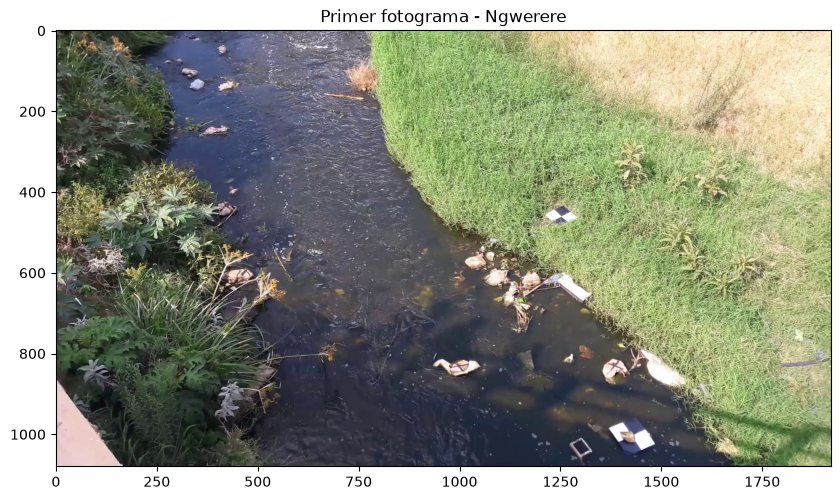

In [2]:
import matplotlib.pyplot as plt
import pyorc

# start_frame/end_frame limitan la lectura: para elegir los GCPs basta con un fotograma.
video = pyorc.Video(str(ARCHIVO_VIDEO), start_frame=0, end_frame=1)

# get_frame devuelve un array numpy. method="rgb" mantiene el color (por defecto seria gris,
# que es lo que usa el PIV, pero el color ayuda a ver los marcadores).
frame = video.get_frame(0, method="rgb")

# Forma (filas, columnas, canales): las filas son la altura y las columnas el ancho.
print(f"Dimensiones del fotograma: {frame.shape}")
print(f"FPS del video: {video.fps}")

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.title("Primer fotograma - Ngwerere")
plt.show()

---
## Parte 2 - Puntos de control (GCPs)

Los GCPs ligan pixeles de la imagen con coordenadas del mundo real medidas con GPS RTK. Son
lo que permite convertir desplazamientos en pixeles a velocidades en metros por segundo.

- `src`: posiciones en la imagen, en pixeles, como `[columna, fila]`
- `dst`: las mismas posiciones en el mundo real, en el mismo orden, en UTM 35S (EPSG:32735)
- `z_0`: cota del nivel del agua durante el video, en la referencia vertical del RTK
- `h_ref`: lectura de la escala limnimetrica durante el video; con un solo video vale 0

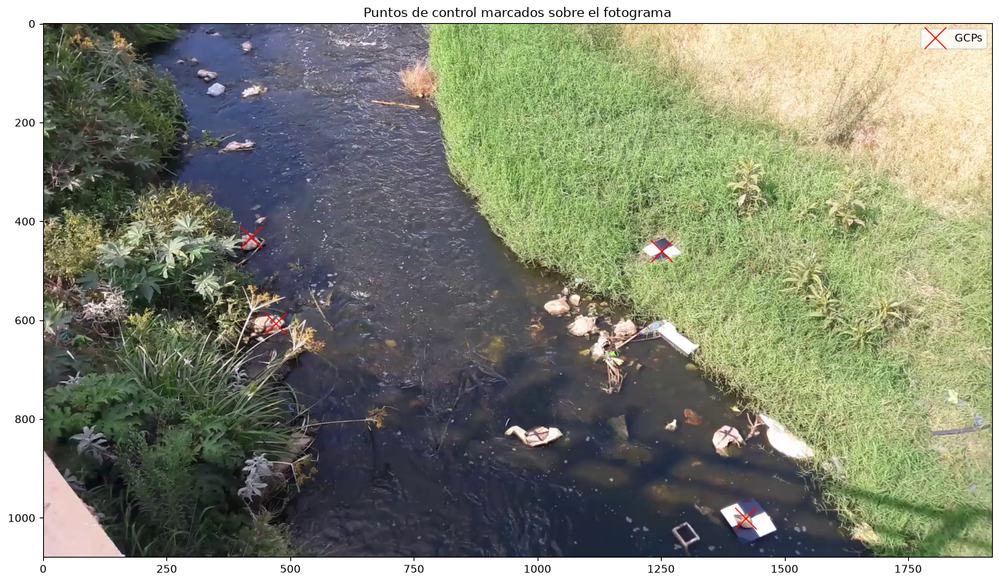

In [3]:
gcps = dict(
    # Coordenadas en pixeles [columna, fila] de los cuatro marcadores.
    src=[
        [1421, 1001],
        [1251, 460],
        [421, 432],
        [470, 607],
    ],
    # Las mismas coordenadas en UTM 35S [este, norte]. El ORDEN debe coincidir con src.
    dst=[
        [642735.8076, 8304292.119],
        [642737.5823, 8304295.593],
        [642732.7864, 8304298.425],
        [642732.6705, 8304296.858],
    ],
    h_ref=0.0,   # nivel local de referencia durante el video (0 al procesar un solo video)
    z_0=1182.2,  # cota absoluta del agua en metros; se usa luego para calcular profundidades
)

plt.figure(figsize=(16, 9))
plt.imshow(frame)
# zip(*gcps["src"]) separa la lista de pares en dos secuencias (columnas, filas);
# el * delante las pasa a plot como los argumentos x e y.
plt.plot(*zip(*gcps["src"]), "rx", markersize=20, label="GCPs")
plt.legend()
plt.title("Puntos de control marcados sobre el fotograma")
plt.show()

---
## Parte 3 - Configuracion de camara y reproyeccion

`CameraConfig` resuelve la transformacion entre pixeles y metros a partir de los GCPs. Ademas
hay que decirle:

- el area de interes (AOI), con cuatro esquinas en pixeles; pyorc encaja un rectangulo
  georreferenciado alrededor
- la resolucion de salida en metros por pixel
- el tamano de la ventana de interrogacion del PIV, en pixeles de la imagen reproyectada

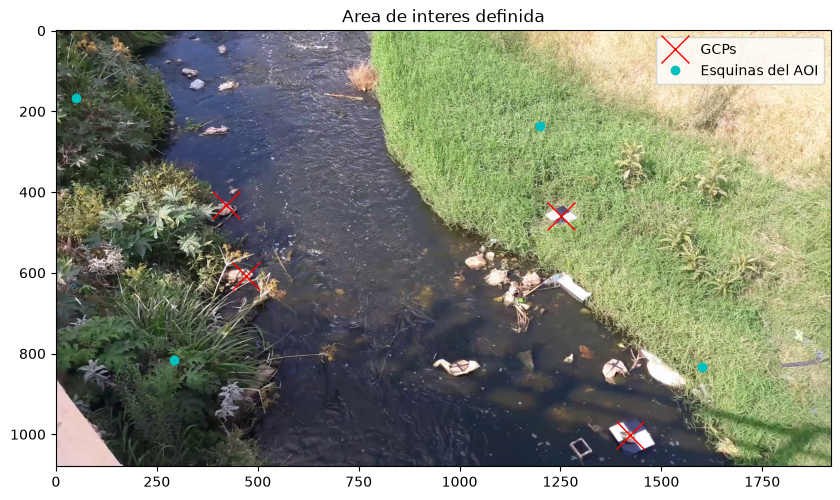

Configuracion guardada en: analisis_ngwerere_verificado\salidas\cam_config_verificado.json


In [4]:
# height y width se toman del propio fotograma para no escribirlos a mano.
cam_config = pyorc.CameraConfig(
    height=frame.shape[0],   # 1080 filas
    width=frame.shape[1],    # 1920 columnas
    gcps=gcps,               # los puntos de control definidos arriba
    crs=32735,               # EPSG:32735 = UTM zona 35S, la zona de Lusaka (Zambia)
)

# Cuatro esquinas del area de interes, en pixeles [columna, fila].
# No hace falta que formen un rectangulo: pyorc ajusta uno en coordenadas reales.
corners = [
    [292, 817],
    [50, 166],
    [1200, 236],
    [1600, 834],
]

# Calcula el rectangulo georreferenciado (bbox) que envuelve esas cuatro esquinas.
cam_config.set_bbox_from_corners(corners)

# Resolucion de la imagen ortorectificada: 0.01 m/pixel = 1 cm por pixel.
cam_config.resolution = 0.01

# Ventana de interrogacion del PIV: 25 pixeles = 25 cm de lado con la resolucion anterior.
# Con solape del 50 % entre ventanas, la malla de velocidades queda a unos 12.5 cm.
cam_config.window_size = 25

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.plot(*zip(*gcps["src"]), "rx", markersize=20, label="GCPs")
plt.plot(*zip(*corners), "co", label="Esquinas del AOI")
plt.legend()
plt.title("Area de interes definida")
plt.show()

# Se guarda en JSON dentro de salidas/, con nombre propio.
cam_config.to_file(str(SALIDA_CAM_CONFIG))
print(f"Configuracion guardada en: {SALIDA_CAM_CONFIG}")

Scanning video:   0%|          | 0/2 [00:00<?, ?it/s]

Scanning video: 100%|██████████| 2/2 [00:00<00:00, 21.89it/s]

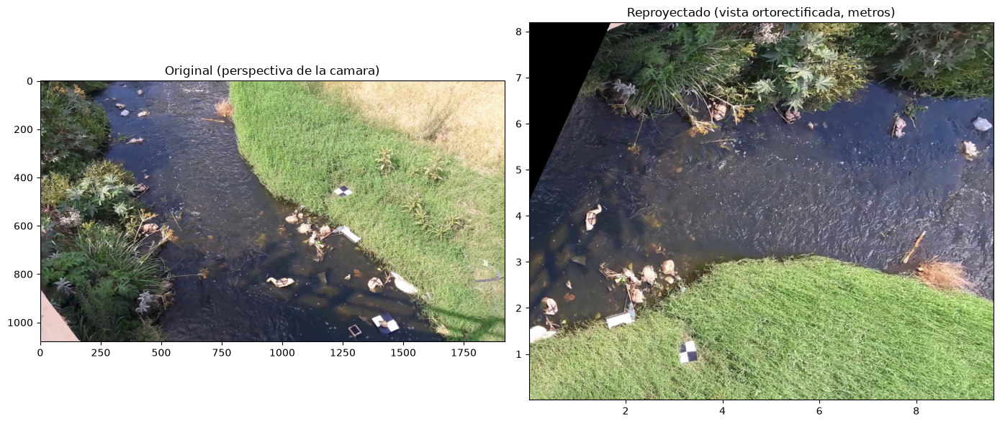

In [5]:
# Comprobacion visual de que la reproyeccion funciona, con un solo fotograma.
video_demo = pyorc.Video(
    str(ARCHIVO_VIDEO),
    camera_config=cam_config,  # al pasar la config, los frames ya saben reproyectarse
    start_frame=0,
    end_frame=1,
    h_a=0.0,                   # nivel del agua de ESTE video respecto a h_ref (mismo video: 0)
)

# get_frames devuelve un xarray.DataArray perezoso (dask); nada se calcula todavia.
da_rgb_demo = video_demo.get_frames(method="rgb")

# .frames es el accesor que pyorc registra en xarray; project ortorectifica a la malla del AOI.
da_rgb_proj_demo = da_rgb_demo.frames.project()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(frame)
axes[0].set_title("Original (perspectiva de la camara)")
# Aqui si se fuerza el calculo, porque hay que dibujar los pixeles.
da_rgb_proj_demo[0].frames.plot(ax=axes[1])
axes[1].set_title("Reproyectado (vista ortorectificada, metros)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig1_reproyeccion.png", dpi=120, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidades superficiales con LSPIV

Ahora se procesa el video completo. La cadena es: estabilizar, pasar a gris, normalizar,
reproyectar y correlacionar pares de fotogramas consecutivos.

`normalize` resta la media de un conjunto de fotogramas, de modo que solo quedan los patrones
que se mueven respecto al fondo: son los trazadores que el PIV puede seguir.

In [6]:
from dask.diagnostics import ProgressBar

# Se recarga la configuracion desde el JSON recien escrito. Es la prueba de que el archivo
# guardado es completo y de que a partir de aqui no depende nada de las celdas anteriores.
cam_config = pyorc.load_camera_config(str(SALIDA_CAM_CONFIG))

# Poligono en pixeles que envuelve la superficie del agua. Todo lo que queda FUERA se
# considera terreno inmovil: cualquier movimiento detectado ahi es temblor de la camara,
# y pyorc lo usa para corregir el resto de la imagen.
stabilize = [
    [150, 0],
    [500, 1079],
    [1750, 1079],
    [900, 0],
]

video = pyorc.Video(
    str(ARCHIVO_VIDEO),
    camera_config=cam_config,
    start_frame=0,
    end_frame=125,        # 126 fotogramas a 30 fps = unos 4.2 s, suficiente para este caso
    stabilize=stabilize,  # activa la correccion de temblor
    h_a=0.0,              # nivel del agua igual al de la medicion de los GCPs
)

# Sin method="rgb" los fotogramas salen en escala de grises, que es lo que necesita el PIV.
da = video.get_frames()

# Resta el fondo (media de varios fotogramas) para realzar los trazadores en movimiento.
da_norm = da.frames.normalize()

# Ortorectifica cada fotograma a la malla del AOI. method="numpy" es la implementacion
# vectorizada; sin ese argumento se usa la de OpenCV.
da_norm_proj = da_norm.frames.project(method="numpy")

print("Calculando velocidades (PIV)...")
# Hasta aqui todo era perezoso. get_piv define el calculo y ProgressBar muestra su avance.
with ProgressBar():
    piv = da_norm_proj.frames.get_piv()

# to_netcdf es lo que dispara realmente el calculo y escribe el resultado a disco.
piv.to_netcdf(SALIDA_PIV_CRUDO)
print(f"Velocimetria cruda guardada en: {SALIDA_PIV_CRUDO}")

Scanning video:   0%|          | 0/126 [00:00<?, ?it/s]

Scanning video:   6%|▋         | 8/126 [00:00<00:01, 79.37it/s]

Scanning video:  21%|██▏       | 27/126 [00:00<00:00, 141.97it/s]

Scanning video:  36%|███▌      | 45/126 [00:00<00:00, 156.67it/s]

Scanning video:  50%|█████     | 63/126 [00:00<00:00, 161.84it/s]

...

[####################################### ] | 98% Completed | 7.25 s

[########################################] | 100% Completed | 7.36 s

Computing PIV per chunk: 100%|██████████| 1/1 [00:22<00:00, 22.74s/it]

Computing PIV per chunk: 100%|██████████| 1/1 [00:22<00:00, 22.74s/it]

Velocimetria cruda guardada en: analisis_ngwerere_verificado\salidas\piv_crudo.nc


Dimensiones del resultado PIV: {'time': 125, 'y': 57, 'x': 67}


Scanning video:   0%|          | 0/126 [00:00<?, ?it/s]

Scanning video:   6%|▋         | 8/126 [00:00<00:01, 77.47it/s]

Scanning video:  18%|█▊        | 23/126 [00:00<00:00, 117.37it/s]

Scanning video:  30%|███       | 38/126 [00:00<00:00, 131.72it/s]

...

Scanning video:  64%|██████▍   | 81/126 [00:00<00:00, 132.76it/s]

Scanning video:  76%|███████▌  | 96/126 [00:00<00:00, 132.81it/s]

Scanning video:  87%|████████▋ | 110/126 [00:00<00:00, 123.91it/s]

Scanning video:  98%|█████████▊| 123/126 [00:00<00:00, 124.38it/s]

Scanning video: 100%|██████████| 126/126 [00:01<00:00, 77.27it/s] 

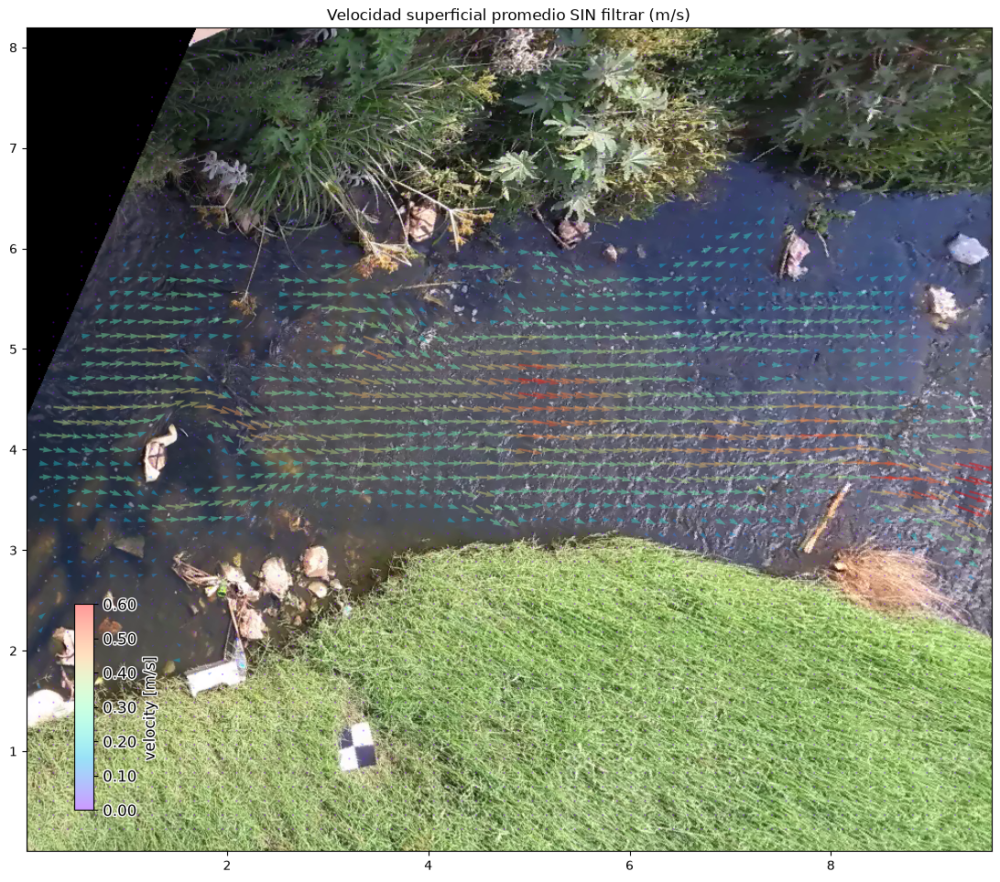

In [7]:
import xarray as xr
from matplotlib.colors import Normalize

# Se relee desde el NetCDF: el dataset trae v_x, v_y, s2n y corr, mas la config de camara
# embebida en los atributos.
ds = xr.open_dataset(SALIDA_PIV_CRUDO)
print(f"Dimensiones del resultado PIV: {dict(ds.sizes)}")

# Se reabre el video sin estabilizar para tener un fotograma en color como fondo.
video_rgb = pyorc.Video(str(ARCHIVO_VIDEO), start_frame=0, end_frame=125)
# La config de camara se recupera del propio dataset, no hay que volver a construirla.
video_rgb.camera_config = ds.velocimetry.camera_config

da_rgb = video_rgb.get_frames(method="rgb")
da_rgb_proj = da_rgb.frames.project()

# No se pueden dibujar tres dimensiones a la vez, asi que se promedia en el tiempo.
# keep_attrs=True conserva la config de camara y los metadatos, que hacen falta para plotear.
ds_mean = ds.mean(dim="time", keep_attrs=True)

p = da_rgb_proj[0].frames.plot()          # fondo ortorectificado en color
ds_mean.velocimetry.plot(                 # flechas de velocidad encima
    ax=p.axes,
    alpha=0.4,
    norm=Normalize(vmax=0.6, clip=False),  # escala de color fija de 0 a 0.6 m/s
    add_colorbar=True,
)
plt.title("Velocidad superficial promedio SIN filtrar (m/s)")
plt.savefig(DIR_SALIDA / "fig2_velocidades_sin_filtrar.png", dpi=120, bbox_inches="tight")
plt.show()

---
## Parte 4b - Filtrado de velocidades espurias

Paso imprescindible. El PIV devuelve un vector por cada ventana de interrogacion, incluidas la
tierra firme, las rocas y las zonas sin trazadores visibles, donde la correlacion es
practicamente ruido. Esos vectores apuntan en direcciones aleatorias y al promediarlos cancelan
parte del flujo real: el caudal sale subestimado y algunos cuantiles pueden salir negativos, lo
cual es fisicamente imposible.

El orden de las mascaras importa cuando se aplican con `inplace=True`, porque cada una
condiciona a la siguiente. El orden recomendado, y el del ejemplo original, es:

1. las que juzgan valores individuales: `corr`, `minmax`
2. las temporales: `rolling`, `outliers`, `variance`
3. las que necesitan la serie completa o la vecindad espacial: `count`, `window_mean`

Vectores validos antes del filtrado: 462144
Vectores validos despues:            111124 (24.0 %)


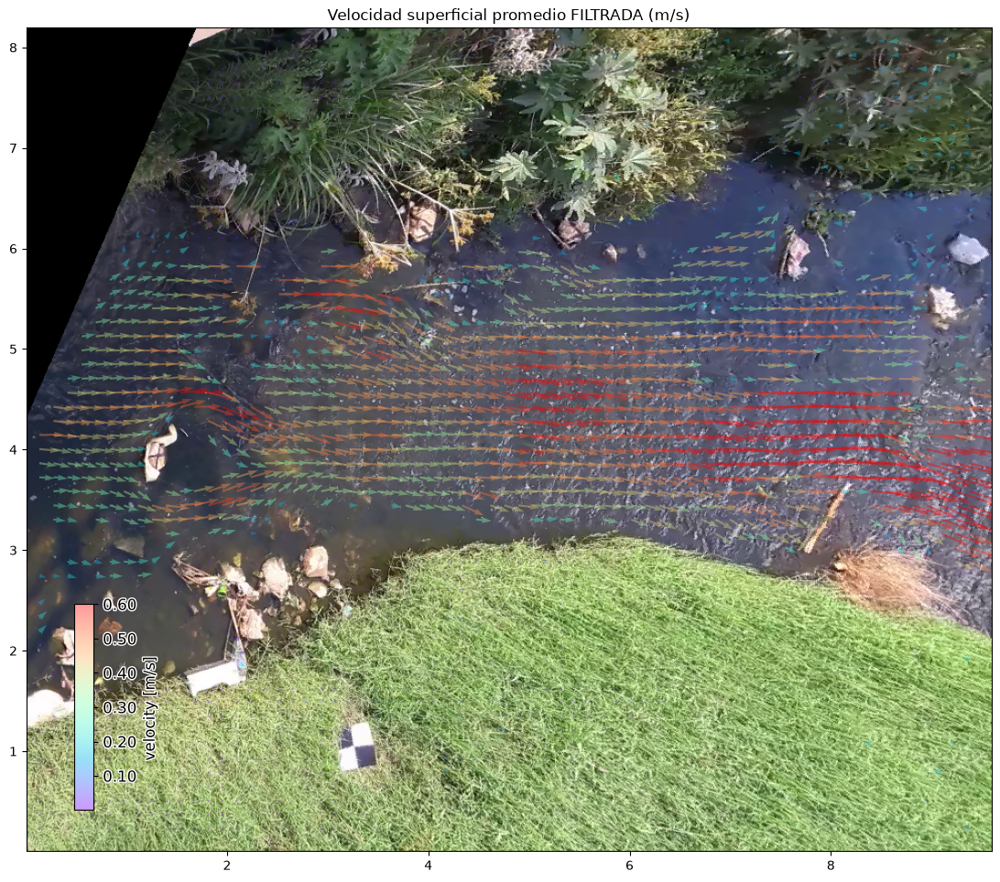

In [8]:
import copy

import numpy as np

# deepcopy para conservar intacto el dataset crudo y poder comparar despues.
ds_mask = copy.deepcopy(ds)

# --- 1) mascaras sobre valores individuales ---
# corr: descarta ventanas cuya correlacion maxima es demasiado baja (no habia patron que seguir).
ds_mask.velocimetry.mask.corr(inplace=True)
# minmax: descarta velocidades fuera de un rango plausible.
ds_mask.velocimetry.mask.minmax(inplace=True)

# --- 2) mascaras en el dominio del tiempo ---
# rolling: compara cada valor con una media movil temporal de su propia celda.
ds_mask.velocimetry.mask.rolling(inplace=True)
# outliers: descarta valores que se apartan demasiado de la media temporal de la celda.
ds_mask.velocimetry.mask.outliers(inplace=True)
# variance: descarta celdas cuya velocidad varia de forma inverosimil a lo largo del tiempo.
ds_mask.velocimetry.mask.variance(inplace=True)

# angle: descartaria los vectores cuya direccion se aparta del flujo esperado (izquierda a
# derecha por defecto). Con angle_tolerance=0.5*pi la tolerancia es de 90 grados, holgada
# porque el agua rodea rocas y cambia de direccion.
# ATENCION: el ejemplo original (03_Plotting_and_masking_velocimetry_results) llama a esta
# mascara SIN inplace=True, a diferencia de todas las demas, asi que la calcula y la descarta:
# nunca se aplica al dataset que luego guarda en ngwerere_masked.nc. Se replica aqui ese mismo
# comportamiento para reproducir el caudal publicado de 0.164 m3/s. Aplicandola de verdad
# (inplace=True) la mediana subiria a unos 0.174 m3/s.
mask_angle = ds_mask.velocimetry.mask.angle(angle_tolerance=0.5 * np.pi)

# --- 3) mascaras que necesitan toda la serie o la vecindad espacial ---
# count: elimina las celdas que, tras los filtros anteriores, se quedaron con muy pocos valores
# validos respecto al total de pasos de tiempo.
ds_mask.velocimetry.mask.count(inplace=True)
# window_mean: compara cada celda con la media de su entorno de 5x5 (wdw=2) sobre el promedio
# temporal (reduce_time=True) y la descarta si se desvia mas de un 50 % (tolerance=0.5).
ds_mask.velocimetry.mask.window_mean(wdw=2, inplace=True, tolerance=0.5, reduce_time=True)

# Promedio temporal del campo ya filtrado, para dibujar y para el mapa final.
ds_mean_mask = ds_mask.mean(dim="time", keep_attrs=True)

# count() sobre un DataArray cuenta solo los valores no nulos: sirve para medir cuanto se filtro.
n_antes = int(ds["v_x"].count())
n_despues = int(ds_mask["v_x"].count())
print(f"Vectores validos antes del filtrado: {n_antes}")
print(f"Vectores validos despues:            {n_despues} ({100 * n_despues / n_antes:.1f} %)")

p = da_rgb_proj[0].frames.plot()
ds_mean_mask.velocimetry.plot(
    ax=p.axes,
    alpha=0.4,
    norm=Normalize(vmax=0.6, clip=False),
    add_colorbar=True,
)
plt.title("Velocidad superficial promedio FILTRADA (m/s)")
plt.savefig(DIR_SALIDA / "fig3_velocidades_filtradas.png", dpi=120, bbox_inches="tight")
plt.show()

In [9]:
# Se guarda el campo filtrado en su propio NetCDF, sin set_encoding(), para que el archivo
# contenga exactamente los mismos valores en coma flotante que se usan en las celdas siguientes.
# (El ejemplo original llama a set_encoding() antes de guardar: comprime a enteros y el archivo
# pesa menos, pero cuantiza ligeramente los valores.)
ds_mask.to_netcdf(SALIDA_PIV_FILTRADO)
print(f"Velocimetria filtrada guardada en: {SALIDA_PIV_FILTRADO}")

Velocimetria filtrada guardada en: analisis_ngwerere_verificado\salidas\piv_filtrado.nc


---
## Parte 5 - Caudal sobre el transecto

Para llegar al caudal hacen falta cuatro pasos:

1. leer la batimetria del transecto (CSV con `x`, `y`, `z` en UTM 35S y en la misma referencia
   vertical que `z_0`)
2. muestrear las velocidades **filtradas** en esos puntos, con `get_transect`
3. rellenar los huecos con un perfil logaritmico y pasar de velocidad superficial a velocidad
   media en la vertical, con `get_q`
4. integrar a lo ancho de la seccion, con `get_river_flow`

In [10]:
import pandas as pd

# El CSV trae tres columnas: x (este UTM), y (norte UTM), z (cota del lecho en metros).
cross_section = pd.read_csv(ARCHIVO_BATIMETRIA)
print(f"Puntos batimetricos medidos: {len(cross_section)}")
cross_section.head()

Puntos batimetricos medidos: 27


,x,y,z
0,642732.215,8304295.847,1182.300
1,642732.378,8304295.817,1182.067
2,642732.541,8304295.787,1182.033
3,642732.704,8304295.756,1182.000
4,642732.876,8304295.725,1182.033


In [11]:
# El muestreo se hace sobre ds_mask (filtrado), NO sobre ds (crudo): es el punto donde el
# filtrado se traduce en el caudal.
transect = ds_mask.velocimetry.get_transect(
    cross_section["x"],
    cross_section["y"],
    cross_section["z"],
    crs=32735,   # el CSV esta en UTM 35S; conviene declararlo aunque coincida con el del dataset
    rolling=4,   # media movil de 4 pasos de tiempo antes de calcular los cuantiles
    # wdw=1 (por defecto) toma la mediana de una ventana de 3x3 celdas alrededor de cada punto.
)

# Los puntos batimetricos se remuestrean a la resolucion de la malla de velocidades, de modo que
# el numero de puntos del transecto no coincide con el del CSV.
print(f"Puntos del transecto tras remuestrear: {transect.sizes['points']}")
print(f"Cuantiles calculados: {transect['quantile'].values}")
transect

Puntos del transecto tras remuestrear: 36
Cuantiles calculados: [0.05 0.25 0.5  0.75 0.95]


<xarray.Dataset> Size: 12kB
Dimensions:       (points: 36, quantile: 5)
Coordinates: (12/13)
    xp            (points) float64 288B 464.1 490.5 516.5 ... 1.23e+03 1.249e+03
    yp            (points) float64 288B 330.2 337.0 343.7 ... 521.9 526.9 531.8
    xs            (points) float64 288B 6.427e+05 6.427e+05 ... 6.427e+05
    ys            (points) float64 288B 8.304e+06 8.304e+06 ... 8.304e+06
    lon           (points) float64 288B 28.33 28.33 28.33 ... 28.33 28.33 28.33
    lat           (points) float64 288B -15.33 -15.33 -15.33 ... -15.33 -15.33
    ...            ...
    y             (points) float64 288B 6.419 6.279 6.14 6.0 ... 1.81 1.67 1.53
    xcoords       (points) float64 288B 6.427e+05 6.427e+05 ... 6.427e+05
    ycoords       (points) float64 288B 8.304e+06 8.304e+06 ... 8.304e+06
    scoords       (points) float64 288B 0.0 0.14 0.28 0.42 ... 4.62 4.76 4.9
    zcoords       (points) float64 288B 1.182e+03 1.182e+03 ... 1.183e+03
  * quantile      (quantile) float64 40B 0.05 0.25 0.5 0.75 0.95
Dimensions without coordinates: points
Data variables:
    s2n           (quantile, points) float64 1kB 16.16 nan nan ... 41.59 41.72
    corr          (quantile, points) float64 1kB 0.4186 nan ... 0.7965 0.8004
    v_x           (quantile, points) float64 1kB -0.1478 nan nan ... 0.2 0.2191
    v_y           (quantile, points) float64 1kB -0.1175 nan nan ... 0.14 0.1319
    cols          (points) float64 288B 19.75 19.68 19.61 ... 17.52 17.45 17.38
    rows          (points) float64 288B 12.26 13.26 14.25 ... 45.18 46.18 47.18
    v_dir         (points) float64 288B -4.646 -4.646 -4.644 ... -4.646 -4.646
    v_eff_nofill  (quantile, points) float64 1kB -0.1397 nan ... 0.1902 0.2098
Attributes:
    camera_shape:   [1080, 1920]
    camera_config:  {\n    "height": 1080,\n    "width": 1920,\n    "crs": "P...
    h_a:            0.0
    chunksize:      20

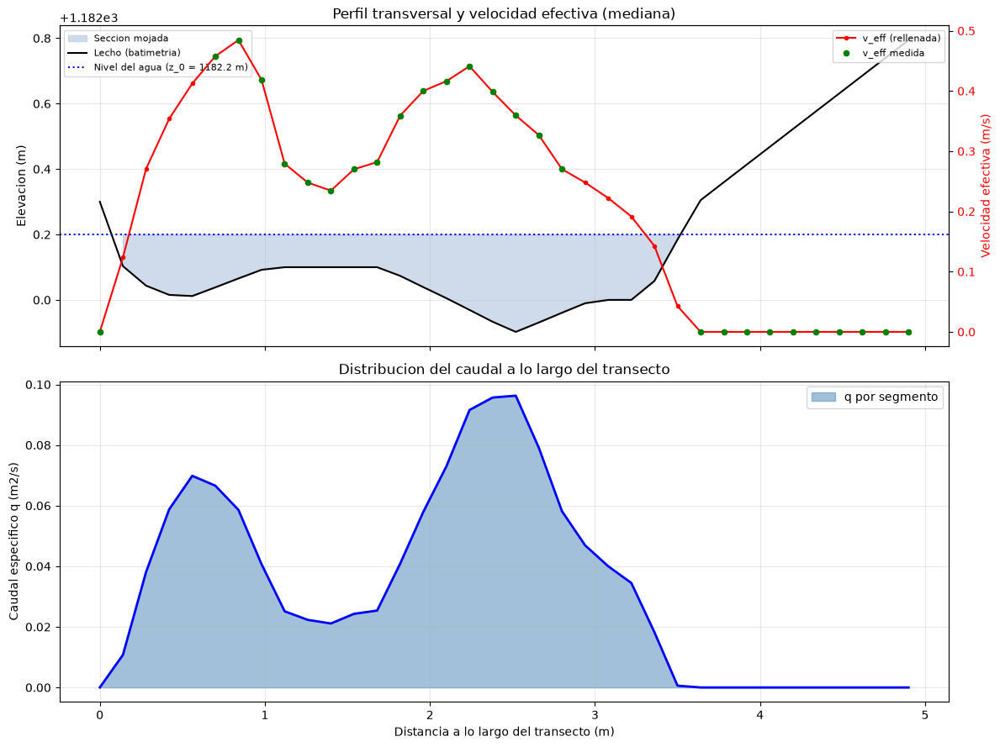

In [12]:
# get_q convierte velocidad superficial en caudal por unidad de ancho.
#   v_corr=0.9: la velocidad media en la vertical se estima como 0.9 veces la superficial.
#   fill_method="log_interp": los huecos sin velocidad valida se rellenan ajustando un perfil
#   logaritmico. Con "zeros" esos huecos valdrian 0 m/s y el caudal quedaria subestimado.
q_transect = transect.transect.get_q(v_corr=0.9, fill_method="log_interp")

# quantile=0.5 es la mediana; es el valor que se compara con el del ejemplo original.
q_med = q_transect.sel(quantile=0.5)

# scoords es la distancia acumulada a lo largo del transecto, en metros desde una orilla.
s = q_med["scoords"].values
# La cota del agua se lee de la propia config de camara, para no repetir el numero a mano.
z_0 = ds_mask.velocimetry.camera_config.gcps["z_0"]

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# --- Panel superior: geometria de la seccion y velocidad efectiva ---
ax_z = axes[0]
# Relleno entre el lecho y la superficie del agua, solo donde el lecho queda por debajo.
ax_z.fill_between(s, q_med["zcoords"].values, z_0,
                  where=q_med["zcoords"].values < z_0,
                  color="lightsteelblue", alpha=0.6, label="Seccion mojada")
ax_z.plot(s, q_med["zcoords"].values, "k-", lw=1.5, label="Lecho (batimetria)")
ax_z.axhline(z_0, color="b", ls=":", lw=1.5, label=f"Nivel del agua (z_0 = {z_0} m)")
ax_z.set_ylabel("Elevacion (m)")
ax_z.set_title("Perfil transversal y velocidad efectiva (mediana)")
ax_z.legend(loc="upper left", fontsize=8)
ax_z.grid(True, alpha=0.3)

# twinx crea un segundo eje y que comparte el eje x, para superponer velocidades a las cotas.
ax_v = ax_z.twinx()
# v_eff: velocidad perpendicular al transecto, ya con los huecos rellenados.
ax_v.plot(s, q_med["v_eff"].values, "r-o", ms=3, lw=1.5, label="v_eff (rellenada)")
# v_eff_nofill: solo los puntos donde realmente hubo medida valida. Los huecos delatan
# cuanta parte del perfil es interpolacion.
ax_v.plot(s, q_med["v_eff_nofill"].values, "g.", ms=9, label="v_eff medida")
ax_v.set_ylabel("Velocidad efectiva (m/s)", color="r")
ax_v.tick_params(axis="y", labelcolor="r")
ax_v.legend(loc="upper right", fontsize=8)

# --- Panel inferior: caudal especifico ---
# q es el caudal por segmento en m2/s: velocidad media en la vertical por profundidad.
axes[1].fill_between(s, q_med["q"].values, alpha=0.5, color="steelblue",
                     label="q por segmento")
axes[1].plot(s, q_med["q"].values, "b-", lw=2)
axes[1].set_xlabel("Distancia a lo largo del transecto (m)")
axes[1].set_ylabel("Caudal especifico q (m2/s)")
axes[1].set_title("Distribucion del caudal a lo largo del transecto")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_perfil_transecto.png", dpi=120, bbox_inches="tight")
plt.show()

In [13]:
# get_river_flow integra q a lo ancho de la seccion y anade la variable river_flow al dataset,
# con un valor por cuantil. Modifica q_transect en el sitio y no devuelve nada util.
q_transect.transect.get_river_flow()
caudal = q_transect["river_flow"]

# Valores publicados por el ejemplo original, notebook
# 04_Extracting_crosssection_velocities_and_discharge, seccion transversal #1.
referencia = [0.07647424, 0.12637030, 0.16405959, 0.19231923, 0.22172388]

print("=" * 62)
print("CAUDAL POR CUANTIL (m3/s)")
print("=" * 62)
print(f"{'cuantil':>8} {'este notebook':>15} {'ejemplo original':>18} {'dif.':>10}")
# zip recorre en paralelo los cuantiles calculados y los valores de referencia.
for qt, ref in zip(caudal["quantile"].values, referencia):
    val = float(caudal.sel(quantile=qt))
    print(f"{qt:>8.2f} {val:>15.4f} {ref:>18.4f} {val - ref:>+10.4f}")

q_med_val = float(caudal.sel(quantile=0.50))  # estimacion central
q_05 = float(caudal.sel(quantile=0.05))       # limite inferior de la banda de incertidumbre
q_95 = float(caudal.sel(quantile=0.95))       # limite superior

print("\n" + "-" * 62)
print(f"Caudal (mediana): {q_med_val:.4f} m3/s   "
      f"[esperado {referencia[2]:.4f} m3/s, dif. {100 * (q_med_val / referencia[2] - 1):+.1f} %]")
print(f"Incertidumbre:    P5 = {q_05:.4f} m3/s   P95 = {q_95:.4f} m3/s")
print("-" * 62)

# Tabla final en CSV, comoda para comparar entre ejecuciones.
resumen = pd.DataFrame({
    "cuantil": caudal["quantile"].values,
    "caudal_m3s": caudal.values,
    "referencia_ejemplo_m3s": referencia,
})
resumen["diferencia_m3s"] = resumen["caudal_m3s"] - resumen["referencia_ejemplo_m3s"]
resumen.to_csv(SALIDA_RESUMEN, index=False)
print(f"\nResumen guardado en: {SALIDA_RESUMEN}")
resumen

CAUDAL POR CUANTIL (m3/s)
 cuantil   este notebook   ejemplo original       dif.
    0.05          0.0757             0.0765    -0.0008
    0.25          0.1250             0.1264    -0.0013
    0.50          0.1672             0.1641    +0.0032
    0.75          0.2047             0.1923    +0.0123
    0.95          0.2405             0.2217    +0.0187

--------------------------------------------------------------
Caudal (mediana): 0.1672 m3/s   [esperado 0.1641 m3/s, dif. +1.9 %]
Incertidumbre:    P5 = 0.0757 m3/s   P95 = 0.2405 m3/s
--------------------------------------------------------------

Resumen guardado en: analisis_ngwerere_verificado\salidas\caudal_resumen.csv


,cuantil,caudal_m3s,referencia_ejemplo_m3s,diferencia_m3s
0,0.05,0.075723,0.076474,-0.000751
1,0.25,0.125038,0.126370,-0.001332
2,0.50,0.167219,0.164060,0.003159
3,0.75,0.204669,0.192319,0.012350
4,0.95,0.240472,0.221724,0.018748


In [14]:
# El transecto completo se guarda tambien en NetCDF: contiene v_eff, q, river_flow y todas
# las coordenadas del muestreo, por si se quiere reanalizar sin repetir el PIV.
q_transect.to_netcdf(SALIDA_TRANSECTO)
print(f"Transecto guardado en: {SALIDA_TRANSECTO}")

Transecto guardado en: analisis_ngwerere_verificado\salidas\transecto_caudal.nc


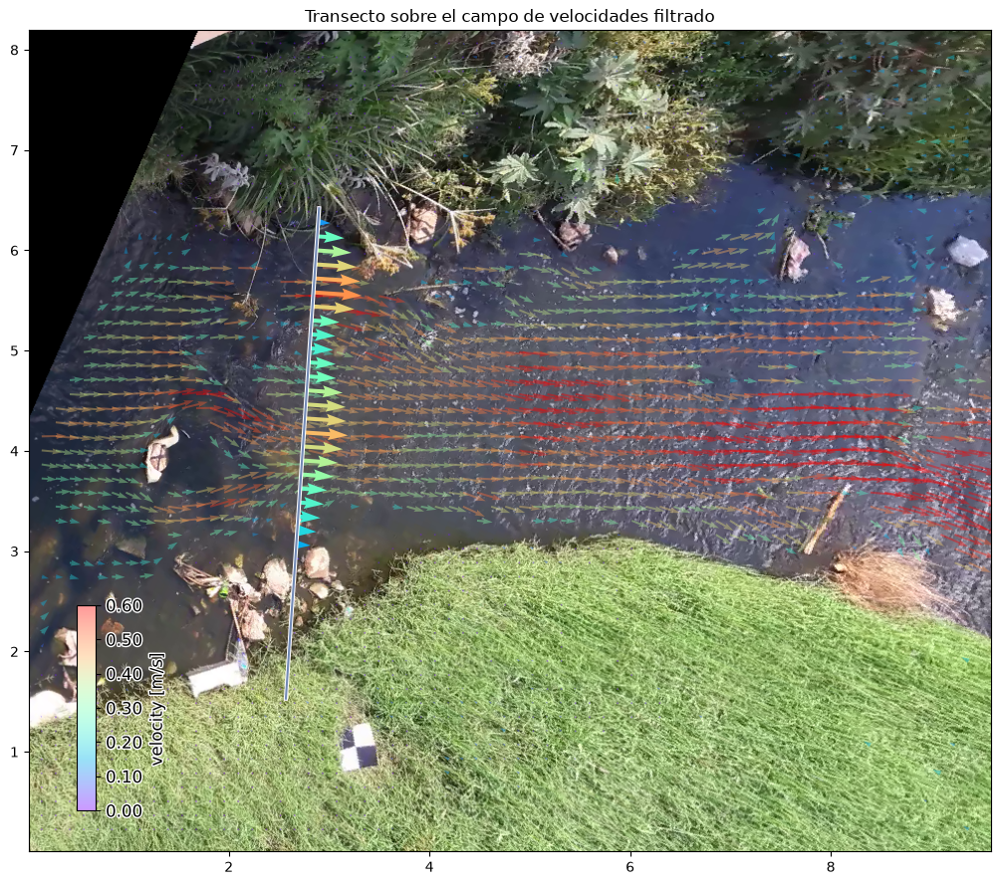

Caudal final (mediana): 0.1672 m3/s


In [15]:
# Mapa final: transecto sobre el campo de velocidades filtrado.
# El fondo se dibuja en proyeccion "local" (metros desde la esquina del AOI), asi que NO se
# pueden pasar las coordenadas UTM del CSV directamente a ax.plot(): caerian fuera del grafico
# y descuadrarian los ejes. Se usa .transect.plot(), que ya conoce las coordenadas locales de
# cada punto muestreado.
norm = Normalize(vmin=0.0, vmax=0.6, clip=False)  # misma escala de color en las dos capas

p = da_rgb_proj[0].frames.plot(mode="local")  # fotograma ortorectificado como fondo

ds_mean_mask.velocimetry.plot(   # campo de velocidades filtrado, como flechas
    ax=p.axes,
    mode="local",
    alpha=0.4,
    norm=norm,
    add_colorbar=True,
)

q_transect.sel(quantile=0.5).transect.plot(  # puntos del transecto, coloreados por v_eff
    ax=p.axes,
    mode="local",
    cmap="rainbow",
    norm=norm,
    width=2,  # grosor relativo de los marcadores; 1 es el valor por defecto
)

p.axes.set_title("Transecto sobre el campo de velocidades filtrado")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig5_mapa_transecto.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Caudal final (mediana): {q_med_val:.4f} m3/s")

---
## Archivos generados

Todo queda en `salidas/`, sin tocar nada del ejemplo original.

In [16]:
# iterdir lista el contenido de la carpeta; sorted lo ordena por nombre.
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    # st_size da el tamano en bytes; se divide entre 1024 para mostrarlo en KiB.
    print(f"  {archivo.name:<34} {archivo.stat().st_size / 1024:>10.1f} KiB")

Contenido de analisis_ngwerere_verificado\salidas:

  cam_config_verificado.json                3.5 KiB
  caudal_resumen.csv                        0.3 KiB
  fig1_reproyeccion.png                  1583.5 KiB
  fig2_velocidades_sin_filtrar.png       2222.7 KiB
  fig3_velocidades_filtradas.png         2212.9 KiB
  fig4_perfil_transecto.png               124.8 KiB
  fig5_mapa_transecto.png                1943.8 KiB
  piv_crudo.nc                           1999.8 KiB
  piv_filtrado.nc                       15119.4 KiB
  transecto_caudal.nc                      45.1 KiB


### Equivalencia con los ejemplos originales

| Este notebook | Ejemplo original |
|---|---|
| Partes 1 a 3 | `01_Camera_Configuration_single_video.ipynb` |
| Parte 4 | `02_Process_velocimetry.ipynb` |
| Parte 4b | `03_Plotting_and_masking_velocimetry_results.ipynb` |
| Parte 5 | `04_Extracting_crosssection_velocities_and_discharge.ipynb` |

### Por que la mediana no coincide al decimal

Queda entre un 1 y un 2 por ciento por encima de los 0.164 m3/s publicados, y el valor cambia
ligeramente de una ejecucion a otra. La razon es que la `CameraConfig` no se puede reproducir bit
a bit: la distancia focal no viene dada, pyorc la estima resolviendo una optimizacion con solo
cuatro puntos de control, y el resultado varia un poco en cada ejecucion. El `ngwerere.json` que
trae el repositorio guarda 1552.16, mientras que pyorc 0.9.8 estima alrededor de 1429 con los
mismos GCPs. Eso cambia levemente el `bbox` y con el los bordes del area analizada. Ejecutando el mismo flujo con el JSON original del
repositorio salen 0.155 m3/s, es decir, el efecto es del mismo orden que la diferencia que queda.
No es un error del procesamiento.

Si se quiere reproducir el valor publicado exactamente, hay que cargar el JSON del repositorio
(`pyorc.load_camera_config(str(DIR_DATOS / "ngwerere.json"))`) en lugar de construir la
configuracion desde los GCPs en la Parte 3.

Aparte, la malla de velocidades sale a 0.14 m de paso en vez de los 0.13 m del ejemplo (36 puntos
de transecto en vez de 39), y eso NO depende de la configuracion de camara: la version actual de
ffpiv redondea `window_size` al par superior (25 pasa a 26) y usa `overlap = 12`, con lo que el
paso es 26 - 12 = 14 px = 0.14 m. En la version con la que se publico el ejemplo era 25 - 12 = 13
px = 0.13 m. Se comprobo cargando el `ngwerere.json` original del repositorio: el paso sigue
saliendo 0.14 m.